<a href="https://colab.research.google.com/github/seungyeonieyo/bpsk/blob/main/bpsk_demodulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

데이터 다운로드 중...


Downloading...
From (original): https://drive.google.com/uc?id=1phfGyTSMMEfoUrQHZe_bIZQDXM01dI2V
From (redirected): https://drive.google.com/uc?id=1phfGyTSMMEfoUrQHZe_bIZQDXM01dI2V&confirm=t&uuid=e2d0d435-f7d5-403f-82d0-adbf407d7147
To: /content/modulated_data_D.csv
100%|██████████| 176M/176M [00:01<00:00, 158MB/s]


데이터 로드 성공: (10000001,)
Phase reversal points at indices: [2423000, 2423600, 2442600, 2443200, 2523000, 2523700, 2542600, 2543300, 2623000, 2623700, 2642600, 2643300, 2723000, 2723700, 2724800, 2725200, 2742600, 2743300, 2744400, 2744800, 2802500, 2804700, 2823000, 2823700, 2824700, 2825300, 2842600, 2843300, 2844300, 2844900, 2902500, 2905100, 2923000, 2923700, 2924600, 2925400, 2942600, 2943300, 2944200, 2945000, 3002500, 3005400, 3023000, 3023700, 3024600, 3025400, 3042600, 3043300, 3044200, 3045000, 3102500, 3105500, 3123000, 3123700, 3124600, 3125400, 3132200, 3132900, 3142600, 3143300, 3144200, 3145000, 3168200, 3168900, 3202500, 3205700, 3223000, 3223700, 3224600, 3225400, 3232200, 3232900, 3242600, 3243300, 3244200, 3245000, 3268200, 3268900, 3302500, 3303200, 3304800, 3305800, 3323000, 3323700, 3324700, 3325300, 3332200, 3332900, 3342600, 3343300, 3344300, 3344900, 3368200, 3368900, 3402500, 3403200, 3405000, 3405900, 3423000, 3423700, 3424800, 3425200, 3432200, 3432900, 344260

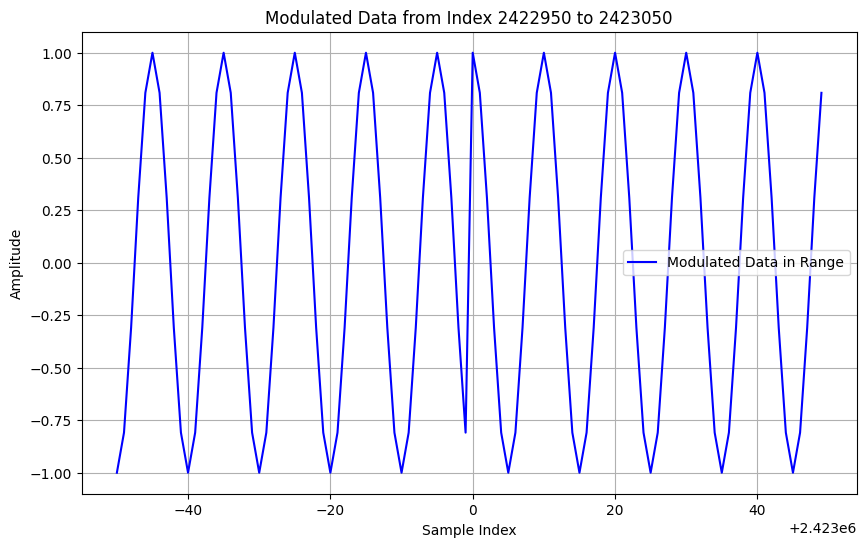

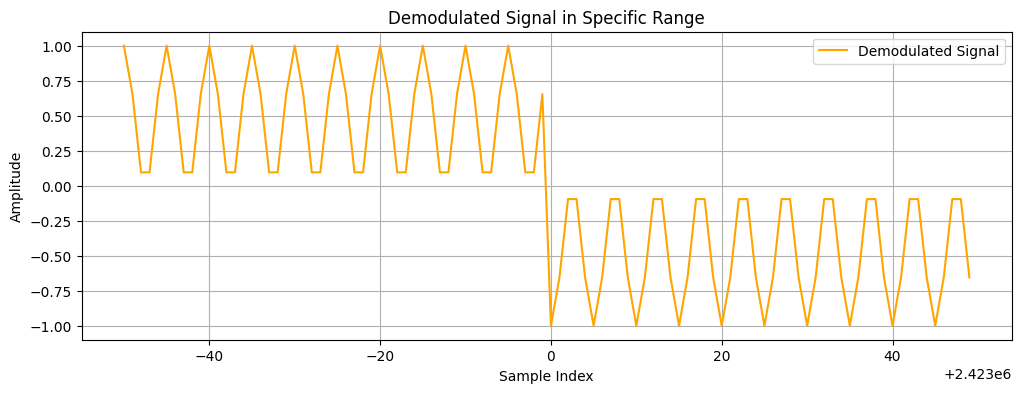

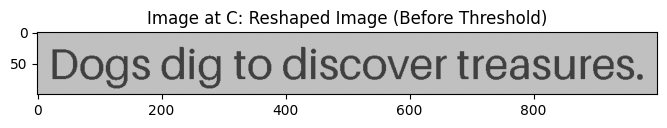

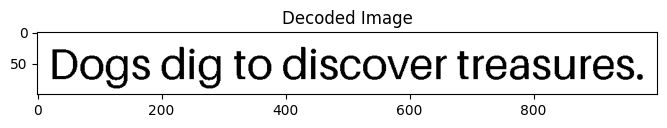

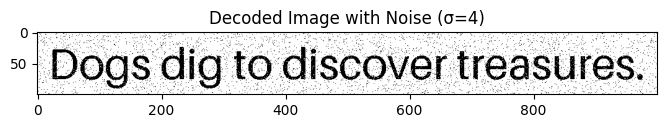

/tmp/ipykernel_8435/2611578791.py:158: RuntimeWarning: divide by zero encountered in log10
  log_ber_list = np.log10(ber_list)


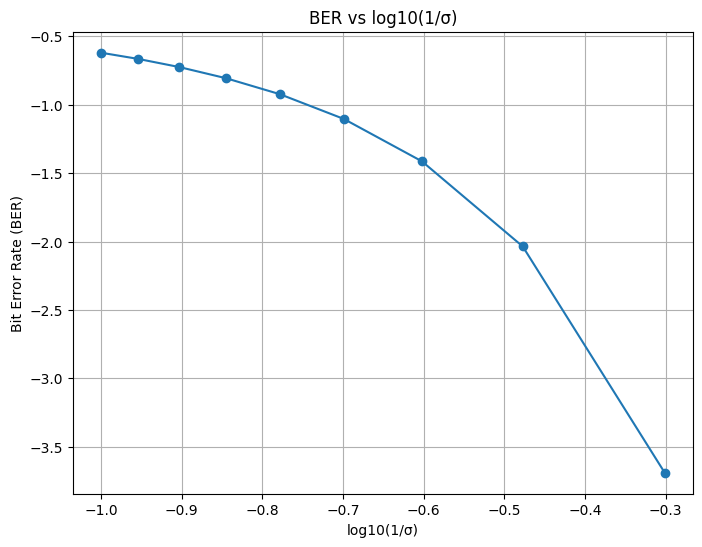

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gdown


file_id = "1phfGyTSMMEfoUrQHZe_bIZQDXM01dI2V"

output = "modulated_data_D.csv"

print("데이터 다운로드 중...")
gdown.download(id=file_id, output=output, quiet=False)


path = output
modulated_data = pd.read_csv(path, header=None).values.flatten()
print("데이터 로드 성공:", modulated_data.shape)

f = 10
time_step = 0.01
num_sample = int(1 / time_step)
t = np.arange(0, 1, time_step)
time = np.arange(0, 1, time_step)

row = 100
col = 1000


if modulated_data[0] == 0:
    modulated_data = modulated_data[1:]


num_periods = len(modulated_data) // num_sample
reversal_points = []

for i in range(1, num_periods):
    start_idx = i * num_sample
    prev_start_idx = (i - 1) * num_sample


    if np.sign(modulated_data[start_idx]) != np.sign(modulated_data[prev_start_idx]):
        reversal_points.append(start_idx)

# Output results
if len(reversal_points) > 0:
    print(f"Phase reversal points at indices: {reversal_points}")
else:
    print("No phase reversal points found.")


start_idx = 2422950
end_idx = 2423050


data_segment = modulated_data[start_idx:end_idx]


x_values = np.arange(start_idx, end_idx)


plt.figure(figsize=(10, 6))
plt.plot(x_values, data_segment, label='Modulated Data in Range', color='blue')
plt.title(f"Modulated Data from Index {start_idx} to {end_idx}")
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()


carrier_signal = np.cos(2 * np.pi * f * t + np.pi)
carrier_signal_full = np.tile(carrier_signal, len(modulated_data) // num_sample)


demodulated_signal = modulated_data * carrier_signal_full


segment_demodulated = demodulated_signal[start_idx:end_idx]

plt.figure(figsize=(12, 4))
plt.plot(range(start_idx, end_idx), segment_demodulated, label="Demodulated Signal", color="orange")
plt.title("Demodulated Signal in Specific Range")
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()
plt.show()


integrated_signal = np.sum(demodulated_signal.reshape(-1, num_sample), axis=1) / num_sample

reshaped_signal = integrated_signal.reshape(row, col)


plt.figure(figsize=(8, 8))
plt.title("Image at C: Reshaped Image (Before Threshold)")
plt.imshow(reshaped_signal, cmap='gray', vmin = -1, vmax= 1)
plt.show()


decoded_data = (integrated_signal > 0).astype(int)


decoded_image = decoded_data.reshape(row, col)


plt.figure(figsize=(8, 8))
plt.title("Decoded Image")
plt.imshow(decoded_image, cmap='gray')
plt.show()



def add_noise(signal, sigma):
    noise = np.random.normal(0, sigma, signal.shape)
    return signal + noise


def decode_bpsk(signal, carrier_signal, row, col):

    demodulated_signal = signal * carrier_signal

    integrated_signal = np.sum(demodulated_signal.reshape(-1, num_sample), axis=1) / num_sample

    reshaped_signal = integrated_signal.reshape(row, col)

    decoded_data = (reshaped_signal > 0).astype(int)
    return decoded_data


sigma = 4
noisy_modulated_data = add_noise(modulated_data, sigma)
decoded_image_noisy = decode_bpsk(noisy_modulated_data, carrier_signal_full, row, col)

plt.figure(figsize=(8, 8))
plt.title("Decoded Image with Noise (σ=4)")
plt.imshow(decoded_image_noisy, cmap='gray')
plt.show()


sigmas = range(1, 11)
ber_list = []
num_trials = 100


decoded_image_clean = decode_bpsk(modulated_data, carrier_signal_full, row, col)

for sigma in sigmas:
    ber_sum = 0
    for _ in range(num_trials):
        noisy_modulated_data = add_noise(modulated_data, sigma)
        decoded_image_noisy = decode_bpsk(noisy_modulated_data, carrier_signal_full, row, col)
        errors = np.sum(decoded_image_noisy.flatten() != decoded_image_clean.flatten())
        ber_sum += errors / (row * col)
    ber_list.append(ber_sum / num_trials)


log_ber_list = np.log10(ber_list)

# Plot BER vs log10(1/σ)
log_inv_sigma = np.log10(1 / np.array(sigmas))
plt.figure(figsize=(8, 6))
plt.plot(log_inv_sigma, log_ber_list, marker='o')
plt.title("BER vs log10(1/σ)")
plt.xlabel("log10(1/σ)")
plt.ylabel("Bit Error Rate (BER)")
plt.grid()
plt.show()